# MiniCode Parte 2 — experimento reproduzível

Execute em Colab com GPU, de cima para baixo, usando uma cópia atualizada do repositório. A hipótese é que QLoRA melhora a acurácia de seleção de ferramenta do mesmo Qwen2.5-0.5B. O teste v2 permanece congelado. O piloto v1 negativo permanece em `experiments/tool_selection/2026-11-22-seed-v1/`.

Condições: checkpoint base 4-bit, o mesmo checkpoint + adapter, e o mesmo adapter sem spec/plano. Decodificação greedy e parser estrito são comuns. A loss supervisiona somente a resposta correta. O teste só será pontuado depois do treinamento com hiperparâmetros fixados; não reajuste este experimento após ver seus resultados.


In [32]:
from pathlib import Path
import os, subprocess, sys
if 'google.colab' in sys.modules or Path('/content').exists():
    from google.colab import drive
    drive.mount('/content/drive')
REPO = Path(os.environ.get('MINICODE_REPO', '/content/drive/MyDrive/redesneurais/MiniCode-parte2'))
assert (REPO / 'requirements-ml.txt').is_file(), 'Copie o pacote atualizado do MiniCode para REPO.'
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(REPO / 'requirements-ml.txt'), 'bitsandbytes==0.48.2'], check=True)
sys.path.insert(0, str(REPO / 'src'))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [33]:
import hashlib, json, platform
from datetime import datetime, timezone
from minicode.selector_protocol import PROTOCOL_VERSION
from minicode.specialization_data import load_examples, validate_examples
from minicode.selector_training import training_dataset, check_supervision, predict, write_json, write_jsonl, sha256_file
DATASET = REPO / 'data/tool_selection/examples.jsonl'
EXPECTED_DATASET_SHA256 = '42393f6ea6e93432c0a7dccca2b7f4700cced33b59a6732fb6065521c81bf3a1'
assert sha256_file(DATASET) == EXPECTED_DATASET_SHA256, 'Dataset mudou; registre novo protocolo antes de treinar.'
rows = load_examples(DATASET)
dataset_report = validate_examples(rows)
splits = {s: [r for r in rows if r['split'] == s] for s in ('train', 'validation', 'test')}
OUT_ROOT = Path(os.environ.get('MINICODE_OUTPUT_ROOT', '/content/drive/MyDrive/redesneurais/minicode-experiments'))
OUT = OUT_ROOT / ('v2-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
OUT.mkdir(parents=True, exist_ok=False)
(OUT / 'dataset.jsonl').write_bytes(DATASET.read_bytes())
CONFIG = {'model': 'Qwen/Qwen2.5-0.5B-Instruct', 'seed': 42, 'epochs': 5, 'learning_rate': 2e-4,
          'batch_size': 1, 'gradient_accumulation_steps': 8, 'max_length': 1024,
          'r': 16, 'alpha': 32, 'dropout': 0.05,
          'target_modules': ['q_proj', 'k_proj', 'v_proj', 'o_proj']}
manifest = {'status': 'configured', 'protocol': PROTOCOL_VERSION, 'config': CONFIG,
            'dataset_sha256': sha256_file(DATASET), 'dataset': dataset_report,
            'code_sha256': {str(p.relative_to(REPO)): sha256_file(p) for p in sorted((REPO/'src/minicode').glob('*.py'))},
            'python': platform.python_version(), 'started_at': datetime.now(timezone.utc).isoformat()}
write_json(OUT/'run_manifest.json', manifest)
print('Saída nova:', OUT, '\\n', dataset_report)


Saída nova: /content/drive/MyDrive/redesneurais/minicode-experiments/v2-20261122T222705957216Z \n {'examples': 96, 'families': 12, 'by_split': {'test': 16, 'train': 64, 'validation': 16}, 'families_by_split': {'test': ['audit_logging', 'retry_timeout'], 'train': ['config_search', 'factorial', 'health_route', 'pagination', 'report_refactor', 'service_tests', 'tax_rounding', 'user_validation'], 'validation': ['cache_invalidation', 'csv_export']}}


## LoRA e QLoRA

Para um peso congelado \(W\in\mathbb{R}^{d_{out}\times d_{in}}\), LoRA aprende \(\Delta W=(\alpha/r)BA\), com \(A\in\mathbb{R}^{r\times d_{in}}\) e \(B\in\mathbb{R}^{d_{out}\times r}\). São \(r(d_{in}+d_{out})\) parâmetros treináveis no lugar de \(d_{in}d_{out}\). QLoRA armazena o peso base em 4 bits, com operações e adaptadores em maior precisão. Rank 16 e módulos de atenção são escolhas fixadas antes da avaliação.

O número real de parâmetros treináveis será registrado abaixo. As losses são sobre a resposta, e não sobre a reprodução do prompt. Elas não equivalem à acurácia top-1.


In [34]:
import torch
from huggingface_hub import HfApi
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, set_seed
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer
if not torch.cuda.is_available():
    raise RuntimeError('Este experimento exige GPU CUDA. O smoke test CPU não substitui o treinamento.')
set_seed(CONFIG['seed'])
MODEL_REVISION = HfApi().model_info(CONFIG['model']).sha
# Exigir suporte nativo; em GPUs como T4, usar autocast FP16.
use_bf16 = torch.cuda.is_bf16_supported(including_emulation=False)
compute_dtype = torch.bfloat16 if use_bf16 else torch.float16
quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=compute_dtype)
tokenizer = AutoTokenizer.from_pretrained(CONFIG['model'], revision=MODEL_REVISION, trust_remote_code=False)
tokenizer.pad_token = tokenizer.eos_token
base_model = AutoModelForCausalLM.from_pretrained(CONFIG['model'], revision=MODEL_REVISION,
    quantization_config=quant, dtype=compute_dtype, device_map={'': 0}, trust_remote_code=False)
manifest.update(status='model_loaded', model_revision=MODEL_REVISION, gpu=torch.cuda.get_device_name(0),
                dtype=str(compute_dtype), torch=torch.__version__, quantization=quant.to_dict())
write_json(OUT/'run_manifest.json', manifest)
# Geração do baseline antes de alterar qualquer peso. A pontuação só é mostrada após treinar.
base_predictions = predict(base_model, tokenizer, splits['test'])
write_jsonl(OUT/'base_test_predictions.jsonl', base_predictions)
print('Baseline preservado; configuração congelada. GPU:', manifest['gpu'])


Baseline preservado; configuração congelada. GPU: Tesla T4


### Precisão do treinamento

O TRL 0.26.2 converte os adaptadores QLoRA para BF16 independentemente de `fp16`. 
A célula abaixo restaura somente os parâmetros treináveis para FP32 antes do otimizador, 
evitando gradientes BF16 no `GradScaler` de FP16. O autocast e o cálculo 4-bit usam a precisão suportada pela GPU.

Após uma tentativa com erro, reinicie a sessão do Colab e execute o notebook atualizado de cima para baixo. 
Isso recria modelo, adaptadores, otimizador e estado do Accelerate em uma nova pasta de saída. 
Não basta repetir `trainer.train()` no objeto que falhou.


In [35]:
lora = LoraConfig(r=CONFIG['r'], lora_alpha=CONFIG['alpha'], lora_dropout=CONFIG['dropout'],
    target_modules=CONFIG['target_modules'], bias='none', task_type='CAUSAL_LM')
training_args = SFTConfig(output_dir=str(OUT/'checkpoints'), seed=CONFIG['seed'], data_seed=CONFIG['seed'],
    num_train_epochs=CONFIG['epochs'], learning_rate=CONFIG['learning_rate'],
    per_device_train_batch_size=CONFIG['batch_size'], per_device_eval_batch_size=1,
    gradient_accumulation_steps=CONFIG['gradient_accumulation_steps'],
    eval_strategy='epoch', logging_steps=1, save_strategy='epoch', save_total_limit=2,
    report_to='none', bf16=use_bf16, fp16=not use_bf16, max_length=CONFIG['max_length'],
    completion_only_loss=True, packing=False, gradient_checkpointing=True)
trainer = SFTTrainer(model=base_model, args=training_args, train_dataset=training_dataset(splits['train']),
    eval_dataset=training_dataset(splits['validation']), processing_class=tokenizer, peft_config=lora)
# TRL 0.26.2 converte os adaptadores QLoRA para BF16 mesmo com fp16=True.
# Corrigir APÓS SFTTrainer e ANTES de criar o otimizador: AMP usa pesos
# treináveis FP32; o modelo base permanece quantizado e o autocast usa FP16/BF16.
with torch.no_grad():
    for parameter in trainer.model.parameters():
        if parameter.requires_grad:
            parameter.data = parameter.data.to(torch.float32)
trainable_dtypes = sorted({str(p.dtype) for p in trainer.model.parameters() if p.requires_grad})
assert trainable_dtypes == ['torch.float32'], f'Precisão treinável inválida: {trainable_dtypes}'
expected_precision = 'bf16' if use_bf16 else 'fp16'
actual_precision = trainer.accelerator.mixed_precision
if actual_precision != expected_precision:
    raise RuntimeError(f'Accelerate usa {actual_precision}, esperado {expected_precision}. Reinicie o runtime e execute tudo.')
manifest['precision'] = {'bf16': training_args.bf16, 'fp16': training_args.fp16,
                         'accelerate': actual_precision, 'trainable_dtypes': trainable_dtypes}
print('Precisão efetiva:', manifest['precision'])
manifest['supervision'] = check_supervision(trainer, [r['label'] for r in splits['train']])
trainable, total = trainer.model.get_nb_trainable_parameters()
manifest.update(status='training', trainable_parameters=trainable, total_parameters=total,
                trainable_fraction=trainable/total)
write_json(OUT/'run_manifest.json', manifest)
trainer.model.print_trainable_parameters()
train_result = trainer.train()
model = trainer.model  # PeftModel efetivo: não usar a referência anterior sem o wrapper.
trainer.save_model(str(OUT/'adapter'))
tokenizer.save_pretrained(str(OUT/'adapter'))
trainer.save_state()
write_json(OUT/'loss_history.json', trainer.state.log_history)
manifest.update(status='trained', training_metrics=train_result.metrics)
write_json(OUT/'run_manifest.json', manifest)


Tokenizing train dataset:   0%|          | 0/64 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/64 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/16 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/16 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151645}.


Precisão efetiva: {'bf16': False, 'fp16': True, 'accelerate': 'fp16', 'trainable_dtypes': ['torch.float32']}
trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359


Epoch,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
1,0.552100,0.575052,2.472688,18759.000000,0.806250
2,0.402200,0.445859,2.695150,37518.000000,0.821875
3,0.296700,0.339499,2.641853,56277.000000,0.884375
4,0.323000,0.245227,2.603895,75036.000000,0.925000
5,0.154800,0.205600,2.595616,93795.000000,0.943750


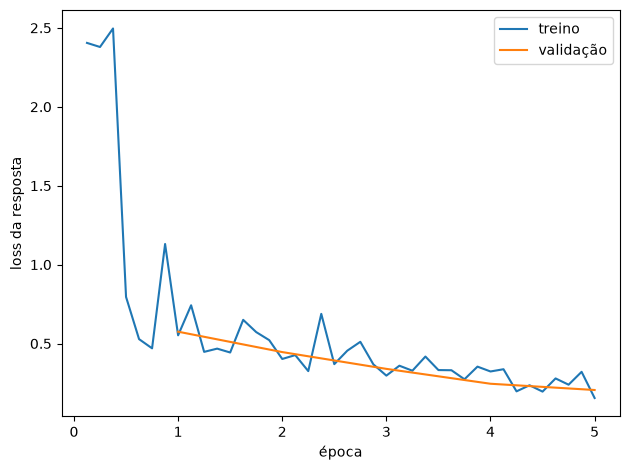

In [36]:
import matplotlib.pyplot as plt
history = trainer.state.log_history
plt.plot([x['epoch'] for x in history if 'loss' in x], [x['loss'] for x in history if 'loss' in x], label='treino')
plt.plot([x['epoch'] for x in history if 'eval_loss' in x], [x['eval_loss'] for x in history if 'eval_loss' in x], label='validação')
plt.legend(); plt.xlabel('época'); plt.ylabel('loss da resposta'); plt.tight_layout()
plt.savefig(OUT/'loss.png', dpi=160); plt.show()


In [37]:
# Todos os modelos usam greedy, mesmo template e limite de tokens. Sem extração permissiva de nomes.
model.eval()
model.config.use_cache = True
runs = {'lora_test': predict(model, tokenizer, splits['test']),
        'lora_no_context_test': predict(model, tokenizer, splits['test'], include_context=False)}
for name, predictions in runs.items():
    write_jsonl(OUT/f'{name}_predictions.jsonl', predictions)
reports = {}
for name in ('base_test', 'lora_test', 'lora_no_context_test'):
    subprocess.run([sys.executable, str(REPO/'scripts/evaluate_tool_selection.py'),
        '--dataset', str(DATASET), '--predictions', str(OUT/f'{name}_predictions.jsonl'),
        '--output', str(OUT/f'{name}_report.json')], check=True)
    reports[name] = json.loads((OUT/f'{name}_report.json').read_text())
write_json(OUT/'comparison.json', {name: {k: report[k] for k in ('examples','correct','accuracy','invalid_predictions')}
                                for name, report in reports.items()})
print(json.dumps(json.loads((OUT/'comparison.json').read_text()), indent=2))


{
  "base_test": {
    "examples": 16,
    "correct": 0,
    "accuracy": 0.0,
    "invalid_predictions": 16
  },
  "lora_test": {
    "examples": 16,
    "correct": 12,
    "accuracy": 0.75,
    "invalid_predictions": 1
  },
  "lora_no_context_test": {
    "examples": 16,
    "correct": 13,
    "accuracy": 0.8125,
    "invalid_predictions": 0
  }
}


In [38]:
# Registrar versões efetivas e hashes; credenciais nunca entram no pacote de resultados.
with (OUT/'environment.txt').open('w') as stream:
    subprocess.run([sys.executable, '-m', 'pip', 'freeze'], check=True, stdout=stream)
manifest.update(status='local_evaluation_complete', ended_at=datetime.now(timezone.utc).isoformat(),
    adapter_files={p.name: sha256_file(p) for p in sorted((OUT/'adapter').iterdir()) if p.is_file()},
    artifact_sha256={p.name: sha256_file(p) for p in sorted(OUT.iterdir()) if p.is_file() and p.name != 'run_manifest.json'})
write_json(OUT/'run_manifest.json', manifest)
import zipfile
with zipfile.ZipFile(OUT/'small_results.zip', 'w', zipfile.ZIP_DEFLATED) as archive:
    for p in sorted(OUT.iterdir()):
        if p.is_file() and p.suffix in {'.json', '.jsonl', '.txt', '.png'}:
            archive.write(p, p.name)
print('Resultados:', OUT/'small_results.zip')
print('Adapter:', OUT/'adapter')


Resultados: /content/drive/MyDrive/redesneurais/minicode-experiments/v2-20261122T222705957216Z/small_results.zip
Adapter: /content/drive/MyDrive/redesneurais/minicode-experiments/v2-20261122T222705957216Z/adapter


## Integração, análise e entrega

Copie o adapter e resultados para `artifacts/` no computador que possui Docker. Execute `scripts/run_part2_experiments.py` seguindo `docs/parte2.md`. O script usa o adapter diretamente, sem exigir que o Colab exponha um servidor público. A bateria compara Qwen sem seletor, Qwen+LoRA e ablação com orçamento total comum.

O dataset é sintético e pequeno, com feedbacks derivados de templates comuns. A ablação remove contexto redundante e pode não mudar o resultado. Isso deve ser relatado. Examine acertos pareados e ferramentas inválidas; não conclua ganho no agente a partir da loss ou da acurácia local.

Referências: [TRL 0.26.2 — prompt-completion e loss](https://huggingface.co/docs/trl/v0.26.2/en/sft_trainer), [PEFT 0.18 — quantização](https://huggingface.co/docs/peft/v0.18.0/en/developer_guides/quantization).
